In [1]:
import glob
import zipfile
import os

archivos = glob.glob('/content/*.zip')

if archivos:
    os.makedirs('/content/oulad_data', exist_ok=True)

    with zipfile.ZipFile(archivos[0], 'r') as zip_ref:
        zip_ref.extractall('/content/oulad_data')

    print("Dataset cargado correctamente")
    print(os.listdir('/content/oulad_data'))
else:
    print("No se encontró el archivo ZIP")

Dataset cargado correctamente
['studentRegistration.csv', 'studentAssessment.csv', 'vle.csv', 'assessments.csv', 'studentInfo.csv', 'studentVle.csv', 'courses.csv']


In [2]:

import os

for carpeta, subcarpetas, archivos in os.walk("/content/oulad_data"):
    for archivo in archivos:
        print(archivo)


studentRegistration.csv
studentAssessment.csv
vle.csv
assessments.csv
studentInfo.csv
studentVle.csv
courses.csv


In [4]:

import pandas as pd
import glob
import os

# Buscar el archivo studentInfo.csv
ruta = glob.glob(
    "/content/oulad_data/**/studentInfo.csv",
    recursive=True
)[0]

# Cargar el dataset
df = pd.read_csv(ruta)

# Mostrar los primeros cinco registros
display(df.head())


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [5]:

# Cantidad de registros y columnas
print("Cantidad de registros:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

# Mostrar los nombres de las variables
print("\nVariables del dataset:")
print(df.columns.tolist())

# Información general
df.info()


Cantidad de registros: 32593
Cantidad de columnas: 12

Variables del dataset:
['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   code_module           32593 non-null  object
 1   code_presentation     32593 non-null  object
 2   id_student            32593 non-null  int64 
 3   gender                32593 non-null  object
 4   region                32593 non-null  object
 5   highest_education     32593 non-null  object
 6   imd_band              31482 non-null  object
 7   age_band              32593 non-null  object
 8   num_of_prev_attempts  32593 non-null  int64 
 9   studied_credits       32593 non-null  int64 
 10  disability         

Resultados académicos:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64


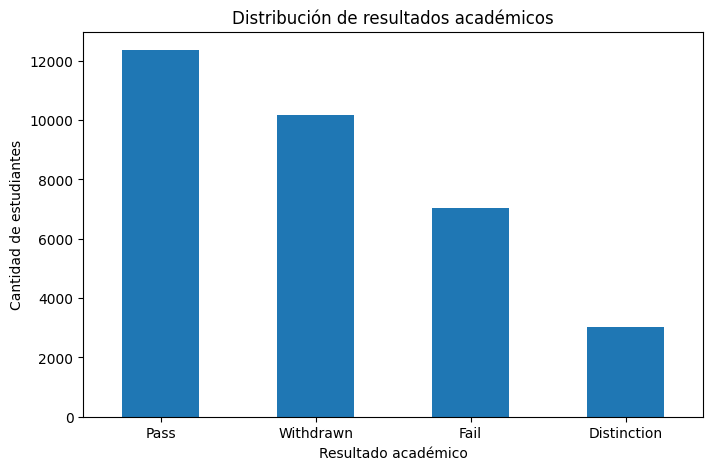

In [6]:

# Distribución de resultados académicos
print("Resultados académicos:")
print(df["final_result"].value_counts())

# Representación gráfica
import matplotlib.pyplot as plt

df["final_result"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribución de resultados académicos")
plt.xlabel("Resultado académico")
plt.ylabel("Cantidad de estudiantes")
plt.xticks(rotation=0)
plt.show()


In [7]:

import pandas as pd
import glob

# Buscar el archivo de interacciones
ruta_vle = glob.glob(
    "/content/oulad_data/**/studentVle.csv",
    recursive=True
)[0]

# Cargar los datos
df_vle = pd.read_csv(ruta_vle)

# Mostrar los primeros registros
display(df_vle.head())

# Conocer el tamaño del dataset
print("Cantidad de registros:", df_vle.shape[0])
print("Cantidad de columnas:", df_vle.shape[1])


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


Cantidad de registros: 10655280
Cantidad de columnas: 6


In [9]:

# Seleccionar los primeros 30 días del curso
df_30 = df_vle[
    (df_vle["date"] >= 0) &
    (df_vle["date"] <= 29)
].copy()

# Calcular indicadores de participación
participacion = df_30.groupby(
    ["code_module", "code_presentation", "id_student"]
).agg(
    total_clicks=("sum_click", "sum"),
    dias_activos=("date", "nunique"),
    recursos_consultados=("id_site", "nunique")
).reset_index()

# Mostrar los primeros registros
display(participacion.head())

# Cantidad de registros
print("Estudiantes con actividad registrada:",
      len(participacion))


,code_module,code_presentation,id_student,total_clicks,dias_activos,recursos_consultados
0,AAA,2013J,11391,321,8,26
1,AAA,2013J,28400,403,12,25
2,AAA,2013J,30268,179,6,17
3,AAA,2013J,31604,334,18,22
4,AAA,2013J,32885,272,16,18


Estudiantes con actividad registrada: 27938


In [10]:

# Seleccionar los primeros 30 días del curso
df_30 = df_vle[
    (df_vle["date"] >= 0) &
    (df_vle["date"] <= 29)
].copy()

# Calcular indicadores de participación
participacion = df_30.groupby(
    ["code_module", "code_presentation", "id_student"]
).agg(
    total_clicks=("sum_click", "sum"),
    dias_activos=("date", "nunique"),
    recursos_consultados=("id_site", "nunique")
).reset_index()

# Mostrar los primeros registros
display(participacion.head())

# Cantidad de registros
print("Estudiantes con actividad registrada:",
      len(participacion))


,code_module,code_presentation,id_student,total_clicks,dias_activos,recursos_consultados
0,AAA,2013J,11391,321,8,26
1,AAA,2013J,28400,403,12,25
2,AAA,2013J,30268,179,6,17
3,AAA,2013J,31604,334,18,22
4,AAA,2013J,32885,272,16,18


Estudiantes con actividad registrada: 27938


In [11]:

# Unir información académica y participación
datos_modelo = pd.merge(
    df,
    participacion,
    on=[
        "code_module",
        "code_presentation",
        "id_student"
    ],
    how="left"
)

# Completar con cero los casos sin actividad
columnas = [
    "total_clicks",
    "dias_activos",
    "recursos_consultados"
]

datos_modelo[columnas] = (
    datos_modelo[columnas].fillna(0)
)

# Mostrar los primeros registros
display(datos_modelo.head())

# Verificar dimensiones
print("Total de registros:", datos_modelo.shape[0])
print("Total de columnas:", datos_modelo.shape[1])

# Verificar resultados académicos
print("\nResultados académicos:")
print(datos_modelo["final_result"].value_counts())


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,total_clicks,dias_activos,recursos_consultados
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,321.0,8.0,26.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,403.0,12.0,25.0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,179.0,6.0,17.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,334.0,18.0,22.0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,272.0,16.0,18.0


Total de registros: 32593
Total de columnas: 15

Resultados académicos:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64


In [12]:

# Verificar las dimensiones del dataset
print("Total de registros:", datos_modelo.shape[0])
print("Total de columnas:", datos_modelo.shape[1])

# Mostrar únicamente las variables principales
columnas_verificar = [
    "id_student",
    "code_module",
    "final_result",
    "total_clicks",
    "dias_activos",
    "recursos_consultados"
]

display(datos_modelo[columnas_verificar].head(10))


Total de registros: 32593
Total de columnas: 15


,id_student,code_module,final_result,total_clicks,dias_activos,recursos_consultados
0,11391,AAA,Pass,321.0,8.0,26.0
1,28400,AAA,Pass,403.0,12.0,25.0
2,30268,AAA,Withdrawn,179.0,6.0,17.0
3,31604,AAA,Pass,334.0,18.0,22.0
4,32885,AAA,Pass,272.0,16.0,18.0
5,38053,AAA,Pass,450.0,23.0,20.0
6,45462,AAA,Pass,381.0,11.0,21.0
7,45642,AAA,Pass,402.0,17.0,24.0
8,52130,AAA,Pass,360.0,17.0,26.0
9,53025,AAA,Pass,395.0,15.0,20.0


In [13]:

# Variables predictoras (X)
X = datos_modelo[
    [
        "total_clicks",
        "dias_activos",
        "recursos_consultados"
    ]
].copy()

# Variable objetivo (y)
y = datos_modelo["final_result"]

# Verificar los datos
print("Variables predictoras:")
display(X.head())

print("\nVariable objetivo:")
display(y.head())

print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


Variables predictoras:


,total_clicks,dias_activos,recursos_consultados
0,321.0,8.0,26.0
1,403.0,12.0,25.0
2,179.0,6.0,17.0
3,334.0,18.0,22.0
4,272.0,16.0,18.0



Variable objetivo:


,final_result
0,Pass
1,Pass
2,Withdrawn
3,Pass
4,Pass



Dimensiones de X: (32593, 3)
Dimensiones de y: (32593,)


In [15]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))


Registros de entrenamiento: 26074
Registros de prueba: 6519


In [16]:

from sklearn.ensemble import RandomForestClassifier

# Crear el modelo Random Forest
modelo = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Entrenar el modelo
modelo.fit(X_train, y_train)

print("Modelo Random Forest entrenado correctamente")


Modelo Random Forest entrenado correctamente


In [17]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report
)

# Realizar predicciones
y_pred = modelo.predict(X_test)

# Calcular métricas
exactitud = accuracy_score(y_test, y_pred)
exactitud_balanceada = balanced_accuracy_score(
    y_test, y_pred
)

print("RESULTADOS DEL MODELO RANDOM FOREST")
print("----------------------------------")

print("Exactitud del modelo:",
      round(exactitud * 100, 2), "%")

print("Exactitud balanceada:",
      round(exactitud_balanceada * 100, 2), "%")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


RESULTADOS DEL MODELO RANDOM FOREST
----------------------------------
Exactitud del modelo: 42.97 %
Exactitud balanceada: 35.29 %

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

 Distinction       0.14      0.11      0.12       605
        Fail       0.27      0.25      0.26      1411
        Pass       0.48      0.55      0.51      2472
   Withdrawn       0.52      0.51      0.51      2031

    accuracy                           0.43      6519
   macro avg       0.36      0.35      0.35      6519
weighted avg       0.42      0.43      0.42      6519



In [18]:

# Seleccionar nuevas variables
variables = [
    "code_module",
    "code_presentation",
    "highest_education",
    "num_of_prev_attempts",
    "studied_credits",
    "total_clicks",
    "dias_activos",
    "recursos_consultados"
]

X_mejorado = datos_modelo[variables].copy()
y_mejorado = datos_modelo["final_result"]

# Verificar información
print("Variables seleccionadas:")
print(X_mejorado.columns.tolist())

print("\nDimensiones:")
print(X_mejorado.shape)

display(X_mejorado.head())


Variables seleccionadas:
['code_module', 'code_presentation', 'highest_education', 'num_of_prev_attempts', 'studied_credits', 'total_clicks', 'dias_activos', 'recursos_consultados']

Dimensiones:
(32593, 8)


,code_module,code_presentation,highest_education,num_of_prev_attempts,studied_credits,total_clicks,dias_activos,recursos_consultados
0,AAA,2013J,HE Qualification,0,240,321.0,8.0,26.0
1,AAA,2013J,HE Qualification,0,60,403.0,12.0,25.0
2,AAA,2013J,A Level or Equivalent,0,60,179.0,6.0,17.0
3,AAA,2013J,A Level or Equivalent,0,60,334.0,18.0,22.0
4,AAA,2013J,Lower Than A Level,0,60,272.0,16.0,18.0


In [19]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Identificar variables categóricas y numéricas
categoricas = X_mejorado.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numericas = X_mejorado.select_dtypes(
    include=["number"]
).columns.tolist()

print("Variables categóricas:", categoricas)
print("Variables numéricas:", numericas)

# Preparación de variables
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            Pipeline([
                ("imputar", SimpleImputer(
                    strategy="most_frequent"
                )),
                ("codificar", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            categoricas
        ),
        (
            "numericas",
            SimpleImputer(strategy="median"),
            numericas
        )
    ]
)

print("\nPreprocesador creado correctamente")


Variables categóricas: ['code_module', 'code_presentation', 'highest_education']
Variables numéricas: ['num_of_prev_attempts', 'studied_credits', 'total_clicks', 'dias_activos', 'recursos_consultados']

Preprocesador creado correctamente


In [20]:

# Conservar los mismos registros del primer experimento
X_train_2 = X_mejorado.loc[X_train.index]
X_test_2 = X_mejorado.loc[X_test.index]

y_train_2 = y_mejorado.loc[y_train.index]
y_test_2 = y_mejorado.loc[y_test.index]

# Crear el segundo modelo
modelo_2 = Pipeline([
    ("preprocesador", preprocesador),
    ("clasificador", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Entrenar
modelo_2.fit(X_train_2, y_train_2)

print("Segundo modelo entrenado correctamente")


Segundo modelo entrenado correctamente


In [21]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report
)

# Realizar predicciones
y_pred_2 = modelo_2.predict(X_test_2)

# Calcular métricas
accuracy_2 = accuracy_score(
    y_test_2, y_pred_2
)

balanced_2 = balanced_accuracy_score(
    y_test_2, y_pred_2
)

print("RESULTADOS DEL SEGUNDO MODELO")
print("-----------------------------")

print("Accuracy:",
      round(accuracy_2 * 100, 2), "%")

print("Balanced Accuracy:",
      round(balanced_2 * 100, 2), "%")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_test_2,
    y_pred_2,
    zero_division=0
))


RESULTADOS DEL SEGUNDO MODELO
-----------------------------
Accuracy: 48.92 %
Balanced Accuracy: 39.59 %

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

 Distinction       0.24      0.12      0.16       605
        Fail       0.31      0.25      0.28      1411
        Pass       0.51      0.66      0.58      2472
   Withdrawn       0.59      0.55      0.57      2031

    accuracy                           0.49      6519
   macro avg       0.41      0.40      0.40      6519
weighted avg       0.47      0.49      0.47      6519



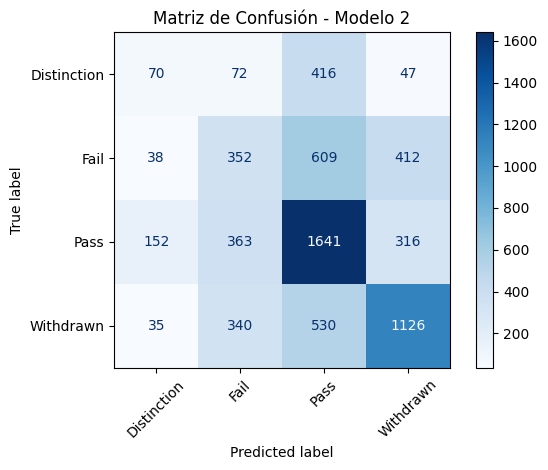

In [22]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Matriz de confusión del segundo modelo
ConfusionMatrixDisplay.from_predictions(
    y_test_2,
    y_pred_2,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Matriz de Confusión - Modelo 2")
plt.tight_layout()
plt.show()


In [23]:

import pandas as pd
import glob

# Buscar archivos
ruta_assessments = glob.glob(
    "/content/oulad_data/**/assessments.csv",
    recursive=True
)[0]

ruta_student_assessment = glob.glob(
    "/content/oulad_data/**/studentAssessment.csv",
    recursive=True
)[0]

# Cargar archivos
df_assessments = pd.read_csv(ruta_assessments)

df_student_assessment = pd.read_csv(
    ruta_student_assessment
)

print("EVALUACIONES")
print("Registros:", df_assessments.shape[0])
display(df_assessments.head())

print("\nRESULTADOS DE ESTUDIANTES")
print("Registros:", df_student_assessment.shape[0])
display(df_student_assessment.head())


EVALUACIONES
Registros: 206


,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0



RESULTADOS DE ESTUDIANTES
Registros: 173912


,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0
3,1752,32885,26,0,69.0
4,1752,38053,19,0,79.0


In [24]:

# Unir evaluaciones con resultados de estudiantes
evaluaciones_completas = pd.merge(
    df_student_assessment,
    df_assessments,
    on="id_assessment",
    how="inner",
    validate="many_to_one"
)

# Mostrar los primeros registros
display(evaluaciones_completas.head())

# Verificar dimensiones
print("Total de registros:",
      evaluaciones_completas.shape[0])

print("Total de columnas:",
      evaluaciones_completas.shape[1])

# Mostrar nombres de variables
print("\nVariables disponibles:")
print(evaluaciones_completas.columns.tolist())


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


Total de registros: 173912
Total de columnas: 10

Variables disponibles:
['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score', 'code_module', 'code_presentation', 'assessment_type', 'date', 'weight']


In [25]:

# Seleccionar evaluaciones tempranas
evaluaciones_30 = evaluaciones_completas[
    (evaluaciones_completas["date"] >= 0) &
    (evaluaciones_completas["date"] <= 29) &
    (evaluaciones_completas["date_submitted"] >= 0) &
    (evaluaciones_completas["date_submitted"] <= 29) &
    (evaluaciones_completas["is_banked"] == 0)
].copy()

print("Evaluaciones tempranas encontradas:",
      len(evaluaciones_30))

display(evaluaciones_30[
    [
        "id_student",
        "code_module",
        "code_presentation",
        "assessment_type",
        "date",
        "date_submitted",
        "score"
    ]
].head(10))


Evaluaciones tempranas encontradas: 20887


,id_student,code_module,code_presentation,assessment_type,date,date_submitted,score
0,11391,AAA,2013J,TMA,19.0,18,78.0
1,28400,AAA,2013J,TMA,19.0,22,70.0
2,31604,AAA,2013J,TMA,19.0,17,72.0
3,32885,AAA,2013J,TMA,19.0,26,69.0
4,38053,AAA,2013J,TMA,19.0,19,79.0
5,45462,AAA,2013J,TMA,19.0,20,70.0
6,45642,AAA,2013J,TMA,19.0,18,72.0
7,52130,AAA,2013J,TMA,19.0,19,72.0
8,53025,AAA,2013J,TMA,19.0,9,71.0
9,57506,AAA,2013J,TMA,19.0,18,68.0


In [26]:

# Calcular indicadores de evaluación
indicadores_evaluacion = evaluaciones_30.groupby(
    ["code_module", "code_presentation", "id_student"]
).agg(
    promedio_calificaciones=("score", "mean"),
    evaluaciones_entregadas=("id_assessment", "nunique")
).reset_index()

# Contar evaluaciones programadas hasta el día 29
evaluaciones_programadas = (
    df_assessments[
        (df_assessments["date"] >= 0) &
        (df_assessments["date"] <= 29)
    ]
    .groupby(["code_module", "code_presentation"])
    .agg(
        total_programadas=("id_assessment", "nunique")
    )
    .reset_index()
)

# Incorporar cantidad de evaluaciones programadas
indicadores_evaluacion = indicadores_evaluacion.merge(
    evaluaciones_programadas,
    on=["code_module", "code_presentation"],
    how="left"
)

# Calcular porcentaje de entregas
indicadores_evaluacion["porcentaje_entregas"] = (
    indicadores_evaluacion["evaluaciones_entregadas"] /
    indicadores_evaluacion["total_programadas"] * 100
)

# Mostrar resultados
display(indicadores_evaluacion.head(10))

print("Registros de estudiantes con evaluaciones:",
      len(indicadores_evaluacion))


,code_module,code_presentation,id_student,promedio_calificaciones,evaluaciones_entregadas,total_programadas,porcentaje_entregas
0,AAA,2013J,11391,78.0,1,1,100.0
1,AAA,2013J,28400,70.0,1,1,100.0
2,AAA,2013J,31604,72.0,1,1,100.0
3,AAA,2013J,32885,69.0,1,1,100.0
4,AAA,2013J,38053,79.0,1,1,100.0
5,AAA,2013J,45462,70.0,1,1,100.0
6,AAA,2013J,45642,72.0,1,1,100.0
7,AAA,2013J,52130,72.0,1,1,100.0
8,AAA,2013J,53025,71.0,1,1,100.0
9,AAA,2013J,57506,68.0,1,1,100.0


Registros de estudiantes con evaluaciones: 19996


In [27]:

# Unir los indicadores de evaluación
datos_modelo_3 = datos_modelo.merge(
    indicadores_evaluacion,
    on=["code_module", "code_presentation", "id_student"],
    how="left",
    validate="one_to_one"
)

# Completar con cero únicamente los conteos de entregas
datos_modelo_3["evaluaciones_entregadas"] = (
    datos_modelo_3["evaluaciones_entregadas"].fillna(0)
)

# Verificar dimensiones
print("Total de registros:", datos_modelo_3.shape[0])
print("Total de columnas:", datos_modelo_3.shape[1])

# Visualizar indicadores
display(datos_modelo_3[
    [
        "id_student",
        "final_result",
        "total_clicks",
        "dias_activos",
        "promedio_calificaciones",
        "evaluaciones_entregadas",
        "porcentaje_entregas"
    ]
].head(10))


Total de registros: 32593
Total de columnas: 19


,id_student,final_result,total_clicks,dias_activos,promedio_calificaciones,evaluaciones_entregadas,porcentaje_entregas
0,11391,Pass,321.0,8.0,78.0,1.0,100.0
1,28400,Pass,403.0,12.0,70.0,1.0,100.0
2,30268,Withdrawn,179.0,6.0,NaN,0.0,NaN
3,31604,Pass,334.0,18.0,72.0,1.0,100.0
4,32885,Pass,272.0,16.0,69.0,1.0,100.0
5,38053,Pass,450.0,23.0,79.0,1.0,100.0
6,45462,Pass,381.0,11.0,70.0,1.0,100.0
7,45642,Pass,402.0,17.0,72.0,1.0,100.0
8,52130,Pass,360.0,17.0,72.0,1.0,100.0
9,53025,Pass,395.0,15.0,71.0,1.0,100.0


In [28]:

# Verificar dimensiones
print("Total de registros:", datos_modelo_3.shape[0])
print("Total de columnas:", datos_modelo_3.shape[1])

# Verificar indicadores de evaluación
columnas = [
    "promedio_calificaciones",
    "evaluaciones_entregadas",
    "total_programadas",
    "porcentaje_entregas"
]

print("\nRESUMEN DE INDICADORES")
display(datos_modelo_3[columnas].describe())

print("\nVALORES AUSENTES")
print(datos_modelo_3[columnas].isnull().sum())


Total de registros: 32593
Total de columnas: 19

RESUMEN DE INDICADORES


,promedio_calificaciones,evaluaciones_entregadas,total_programadas,porcentaje_entregas
count,19983.000000,32593.000000,19996.000000,19996.000000
mean,72.377346,0.640843,1.050960,99.679936
std,22.054516,0.533710,0.219922,3.987675
min,0.000000,0.000000,1.000000,50.000000
25%,64.000000,0.000000,1.000000,100.000000
50%,77.000000,1.000000,1.000000,100.000000
75%,87.000000,1.000000,1.000000,100.000000
max,100.000000,2.000000,2.000000,100.000000



VALORES AUSENTES
promedio_calificaciones    12610
evaluaciones_entregadas        0
total_programadas          12597
porcentaje_entregas        12597
dtype: int64


In [29]:

# Variables del tercer modelo
variables_3 = [
    "code_module",
    "code_presentation",
    "highest_education",
    "num_of_prev_attempts",
    "studied_credits",
    "total_clicks",
    "dias_activos",
    "recursos_consultados",
    "promedio_calificaciones",
    "evaluaciones_entregadas",
    "porcentaje_entregas"
]

X_3 = datos_modelo_3[variables_3].copy()
y_3 = datos_modelo_3["final_result"]

print("Variables predictoras:", X_3.shape[1])
print("Registros:", X_3.shape[0])

display(X_3.head())


Variables predictoras: 11
Registros: 32593


,code_module,code_presentation,highest_education,num_of_prev_attempts,studied_credits,total_clicks,dias_activos,recursos_consultados,promedio_calificaciones,evaluaciones_entregadas,porcentaje_entregas
0,AAA,2013J,HE Qualification,0,240,321.0,8.0,26.0,78.0,1.0,100.0
1,AAA,2013J,HE Qualification,0,60,403.0,12.0,25.0,70.0,1.0,100.0
2,AAA,2013J,A Level or Equivalent,0,60,179.0,6.0,17.0,NaN,0.0,NaN
3,AAA,2013J,A Level or Equivalent,0,60,334.0,18.0,22.0,72.0,1.0,100.0
4,AAA,2013J,Lower Than A Level,0,60,272.0,16.0,18.0,69.0,1.0,100.0


In [30]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Identificar variables categóricas
categoricas_3 = X_3.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Identificar variables numéricas
numericas_3 = X_3.select_dtypes(
    include=["number"]
).columns.tolist()

# Preparar las variables
preprocesador_3 = ColumnTransformer([
    (
        "categoricas",
        Pipeline([
            ("imputar", SimpleImputer(
                strategy="most_frequent"
            )),
            ("codificar", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ]),
        categoricas_3
    ),
    (
        "numericas",
        SimpleImputer(strategy="median"),
        numericas_3
    )
])

# Crear el modelo
modelo_3 = Pipeline([
    ("preprocesador", preprocesador_3),
    ("clasificador", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

print("Tercer modelo preparado correctamente")


Tercer modelo preparado correctamente


In [31]:

# Utilizar los mismos registros del modelo anterior
X_train_3 = X_3.loc[X_train.index]
X_test_3 = X_3.loc[X_test.index]

y_train_3 = y_3.loc[y_train.index]
y_test_3 = y_3.loc[y_test.index]

# Entrenar Random Forest
modelo_3.fit(X_train_3, y_train_3)

print("Tercer modelo Random Forest entrenado correctamente")


Tercer modelo Random Forest entrenado correctamente


In [32]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report
)

# Generar predicciones
y_pred_3 = modelo_3.predict(X_test_3)

# Calcular métricas
accuracy_3 = accuracy_score(
    y_test_3, y_pred_3
)

balanced_3 = balanced_accuracy_score(
    y_test_3, y_pred_3
)

print("RESULTADOS DEL TERCER MODELO")
print("---------------------------")

print("Accuracy:",
      round(accuracy_3 * 100, 2), "%")

print("Balanced Accuracy:",
      round(balanced_3 * 100, 2), "%")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_test_3,
    y_pred_3,
    zero_division=0
))


RESULTADOS DEL TERCER MODELO
---------------------------
Accuracy: 53.35 %
Balanced Accuracy: 43.93 %

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

 Distinction       0.35      0.18      0.23       605
        Fail       0.35      0.26      0.30      1411
        Pass       0.54      0.73      0.62      2472
   Withdrawn       0.66      0.60      0.62      2031

    accuracy                           0.53      6519
   macro avg       0.47      0.44      0.44      6519
weighted avg       0.52      0.53      0.52      6519



In [33]:

# Motor inicial de recomendaciones pedagógicas

def recomendar_actividades(
    total_clicks,
    dias_activos,
    recursos_consultados
):
    recomendaciones = []

    # Regla 1: Participación limitada
    if dias_activos < 5:
        recomendaciones.append({
            "Necesidad": "Participación limitada",
            "Estrategia": "Aprendizaje activo",
            "Actividad": "Foro de debate en Moodle"
        })

    # Regla 2: Pocos recursos consultados
    if recursos_consultados < 3:
        recomendaciones.append({
            "Necesidad": "Exploración limitada de recursos",
            "Estrategia": "Aprendizaje guiado",
            "Actividad": "Lección interactiva en Moodle"
        })

    # Regla 3: Baja cantidad de interacciones
    if total_clicks < 50:
        recomendaciones.append({
            "Necesidad": "Baja interacción",
            "Estrategia": "Gamificación",
            "Actividad": "Cuestionario interactivo"
        })

    # Si no se detectan estas condiciones
    if not recomendaciones:
        recomendaciones.append({
            "Necesidad": "Seguimiento del aprendizaje",
            "Estrategia": "Evaluación formativa",
            "Actividad": "Cuestionario de autoevaluación"
        })

    return recomendaciones

print("Motor de recomendaciones creado correctamente")


Motor de recomendaciones creado correctamente


In [34]:

import pandas as pd

# Datos de ejemplo
total_clicks = 30
dias_activos = 3
recursos_consultados = 2

# Generar recomendaciones
resultado = recomendar_actividades(
    total_clicks,
    dias_activos,
    recursos_consultados
)

# Mostrar resultados
display(pd.DataFrame(resultado))


,Necesidad,Estrategia,Actividad
0,Participación limitada,Aprendizaje activo,Foro de debate en Moodle
1,Exploración limitada de recursos,Aprendizaje guiado,Lección interactiva en Moodle
2,Baja interacción,Gamificación,Cuestionario interactivo
